In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score


from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

## **1) ΔΕΔΟΜΕΝΑ ΚΑΙ ΠΡΟΕΤΟΙΜΑΣΙΑ**
### **ΦΟΡΤΩΣΗ ΚΑΙ ΒΑΣΙΚΑ ΣΤΟΙΧΕΙΑ ΔΕΔΟΜΕΝΩΝ**

In [3]:
#Διαβάζει τα δεδομένα 
df = pd.read_csv("data_Fraud.csv")

In [4]:
df.head()

,fyear,gvkey,p_aaer,misstate,act,ap,at,ceq,che,cogs,...,soft_assets,ch_cs,ch_cm,ch_roa,issue,bm,dpi,reoa,EBIT,ch_fcf
0,1990,1009,NaN,0,10.047,3.736,32.335,6.262,0.002,30.633,...,0.312448,0.095082,0.082631,-0.019761,1,0.413170,0.873555,0.167620,0.161961,-0.042140
1,1990,1011,NaN,0,1.247,0.803,7.784,0.667,0.171,1.125,...,0.315904,0.188832,-0.211389,-0.117832,1,0.157887,0.745139,-0.428957,-0.157888,0.100228
2,1990,1017,NaN,0,55.040,3.601,118.120,44.393,3.132,107.343,...,0.605342,0.097551,-0.105780,0.091206,1,2.231337,1.015131,0.394768,0.063681,0.066348
3,1990,1021,NaN,0,24.684,3.948,34.591,7.751,0.411,31.214,...,0.793068,-0.005725,-0.249704,0.017545,1,1.043582,1.026261,0.094822,0.088347,-0.017358
4,1990,1028,NaN,0,17.325,3.520,27.542,-12.142,1.017,32.662,...,0.869182,-0.231536,-1.674893,-0.466667,0,-1.602508,0.598443,-0.942379,-0.700821,0.130349


In [5]:
#Τα δεδομένα έχουν 146045 γραμμές και 46 στήλες
print(df.shape) 

(146045, 46)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 146045 entries, 0 to 146044
Data columns (total 46 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   fyear        146045 non-null  int64  
 1   gvkey        146045 non-null  int64  
 2   p_aaer       964 non-null     float64
 3   misstate     146045 non-null  int64  
 4   act          146045 non-null  float64
 5   ap           146045 non-null  float64
 6   at           146045 non-null  float64
 7   ceq          146045 non-null  float64
 8   che          146045 non-null  float64
 9   cogs         146045 non-null  float64
 10  csho         146045 non-null  float64
 11  dlc          146045 non-null  float64
 12  dltis        146045 non-null  float64
 13  dltt         146045 non-null  float64
 14  dp           146045 non-null  float64
 15  ib           146045 non-null  float64
 16  invt         146045 non-null  float64
 17  ivao         146045 non-null  float64
 18  ivst         146045 non-null  float

In [7]:
#Οι στήλες του dataset είναι οι εξής:
df.columns

Index(['fyear', 'gvkey', 'p_aaer', 'misstate', 'act', 'ap', 'at', 'ceq', 'che',
       'cogs', 'csho', 'dlc', 'dltis', 'dltt', 'dp', 'ib', 'invt', 'ivao',
       'ivst', 'lct', 'lt', 'ni', 'ppegt', 'pstk', 're', 'rect', 'sale',
       'sstk', 'txp', 'txt', 'xint', 'prcc_f', 'dch_wc', 'ch_rsst', 'dch_rec',
       'dch_inv', 'soft_assets', 'ch_cs', 'ch_cm', 'ch_roa', 'issue', 'bm',
       'dpi', 'reoa', 'EBIT', 'ch_fcf'],
      dtype='str')

In [8]:
#Το εύρος των ετών είναι από το 1990 εως το 2014
print(df['fyear'].min(), "-", df['fyear'].max())

1990 - 2014


In [9]:
#Περιγραφικά στατιστιά στοιχεία για το dataset
df.describe() 

,fyear,gvkey,p_aaer,misstate,act,ap,at,ceq,che,cogs,...,soft_assets,ch_cs,ch_cm,ch_roa,issue,bm,dpi,reoa,EBIT,ch_fcf
count,146045.000000,146045.000000,964.000000,146045.000000,146045.000000,146045.000000,146045.000000,146045.000000,146045.000000,146045.000000,...,145453.000000,130127.000000,128938.000000,133367.000000,146045.000000,146027.000000,136817.000000,145454.000000,145454.000000,140638.000000
mean,2002.011702,54243.435516,2503.840249,0.006601,737.847759,181.993488,2374.041576,887.126243,218.657186,1302.280756,...,0.499790,0.185169,-0.090980,-0.010208,0.863487,0.466137,1.042207,-3.191197,-0.238754,-0.008842
std,6.959894,59937.455765,912.093250,0.080976,3744.542368,1047.546104,11957.736980,5056.948150,1330.490185,7870.665783,...,0.274129,1.383354,2.844807,0.379574,0.343333,1.314661,0.495286,12.932219,1.059134,0.548216
min,1990.000000,1004.000000,371.000000,0.000000,-0.254000,0.000000,0.000000,-25560.000000,-34.000000,-366.645000,...,0.004515,-6.484197,-17.359699,-1.671565,0.000000,-7.034304,0.151757,-89.013245,-7.016393,-2.980601
25%,1996.000000,10658.000000,1803.000000,0.000000,8.277000,1.151000,18.281000,6.337000,1.144000,6.795000,...,0.270023,-0.073635,-0.260164,-0.058635,1.000000,0.191546,0.854248,-0.894633,-0.128135,-0.123402
50%,2002.000000,25088.000000,2620.500000,0.000000,47.501000,6.462000,105.346000,47.308000,9.373000,53.382000,...,0.524640,0.067918,-0.023205,-0.001893,1.000000,0.442172,0.974302,-0.008046,0.043701,-0.026155
75%,2008.000000,66586.000000,3180.000000,0.000000,249.832000,42.259000,672.929000,271.547000,60.286000,372.730000,...,0.726663,0.250237,0.139960,0.042188,1.000000,0.805320,1.097582,0.229724,0.108059,0.062294
max,2014.000000,317264.000000,3996.000000,1.000000,152629.000000,39903.000000,410074.000000,284434.000000,85709.000000,435726.253000,...,0.993599,9.600000,16.573810,1.621628,1.000000,4.937457,4.036458,0.784573,0.550619,4.061810


In [10]:
#Το ποσοστό της κάθε κλάσης στην στήλη misstate (0 = No Fraud, 1 = Fraud)
print(df['misstate'].value_counts())
print(df['misstate'].value_counts(normalize=True) * 100) #εμφανιση σε ποσοστο

misstate
0    145081
1       964
Name: count, dtype: int64
misstate
0    99.339929
1     0.660071
Name: proportion, dtype: float64


In [11]:
#Μου δείχνει πόσες παρατηρήσεις έχει κάθε έτος και πόσες από αυτές είναι fraud (misstate = 1)
print(df.groupby("fyear")["misstate"].agg(["count","sum"]))

       count  sum
fyear            
1990    4582   15
1991    4713   27
1992    4970   26
1993    5377   30
1994    5684   23
1995    6230   22
1996    6745   33
1997    6789   42
1998    6716   56
1999    6828   73
2000    6752   86
2001    6362   81
2002    6067   77
2003    5981   69
2004    5934   58
2005    5863   45
2006    5908   33
2007    5868   30
2008    5612   26
2009    5367   31
2010    5389   26
2011    5404   21
2012    5630   19
2013    5647   11
2014    5627    4


### **ΟΠΤΙΚΟΠΟΙΗΣΗ ΤΟΥ ΣΥΝΟΛΟΥ ΔΕΔΟΜΕΝΩΝ - EDA**

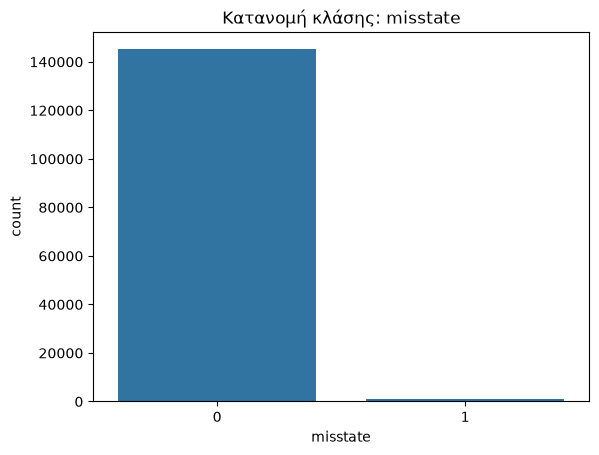

In [12]:
#Κατανομή κλάσης misstate
sns.countplot(x='misstate', data=df)
plt.title('Κατανομή κλάσης: misstate')
plt.show()

In [13]:
#Ποσοστό απάτης ανά χρονιά 
print(df.groupby('fyear')['misstate'].mean() * 100)

fyear
1990    0.327368
1991    0.572884
1992    0.523139
1993    0.557932
1994    0.404645
1995    0.353130
1996    0.489251
1997    0.618648
1998    0.833830
1999    1.069127
2000    1.273697
2001    1.273185
2002    1.269161
2003    1.153653
2004    0.977418
2005    0.767525
2006    0.558565
2007    0.511247
2008    0.463293
2009    0.577604
2010    0.482464
2011    0.388601
2012    0.337478
2013    0.194794
2014    0.071086
Name: misstate, dtype: float64


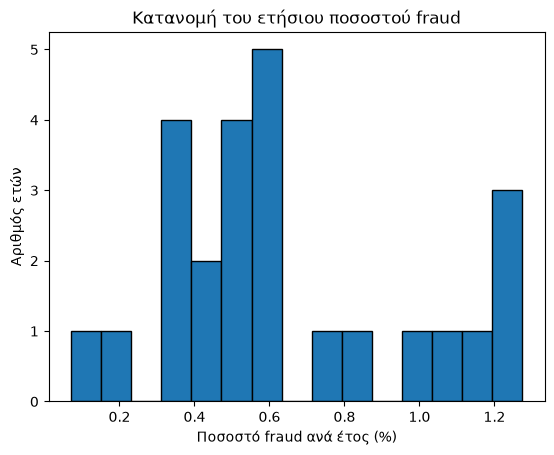

In [14]:
fraud_rate_by_year = df.groupby('fyear')['misstate'].mean() * 100

plt.hist(fraud_rate_by_year, bins=15, edgecolor='black')
plt.xlabel('Ποσοστό fraud ανά έτος (%)')
plt.ylabel('Αριθμός ετών')
plt.title('Κατανομή του ετήσιου ποσοστού fraud')
plt.show()

##### Το παραπάνω διάγραμμα μας δείχνει το πλήθος των ετών που αντιστοιχεί σε κάθε fraud rate. Παρατηρούμε ότι το πιο σύνηθες ποσοστό απάτης το οποίο αντιστοιχεί σε 5 διαφορετικά έτη είναι περίπου 0,6%

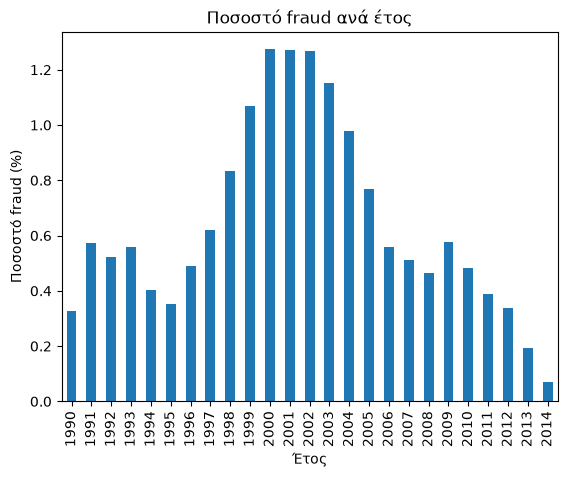

In [15]:
fraud_rate_by_year.plot(kind='bar')
plt.xlabel('Έτος')
plt.ylabel('Ποσοστό fraud (%)')
plt.title('Ποσοστό fraud ανά έτος')
plt.show()

##### Το παραπάνω διάγραμμα απεικονίζει για κάθε έτος ποιό είναι το ποσοστό απάτης. Παρατηρούμε πως τις χρονιές 2000-2002 παρατηρούνται τα μεγαλύτερα ποσοσστά απάτης ύψους 1,2% περίπου και στη συνέχεια μειώνονται.

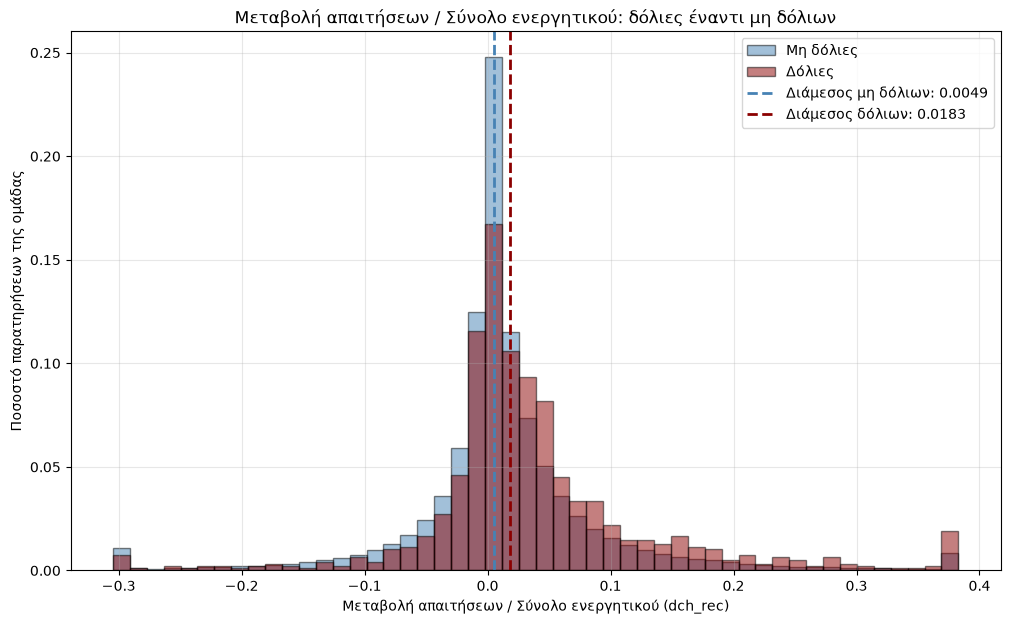

In [16]:
fraud = df.loc[df['misstate'] == 1, 'dch_rec'].dropna()
non_fraud = df.loc[df['misstate'] == 0, 'dch_rec'].dropna()

plt.figure(figsize=(12, 7))
plt.hist(non_fraud, bins=50,
         weights=np.ones(len(non_fraud)) / len(non_fraud),
         alpha=0.5, color='steelblue', edgecolor='black', label='Μη δόλιες')
plt.hist(fraud, bins=50,
         weights=np.ones(len(fraud)) / len(fraud),
         alpha=0.5, color='darkred', edgecolor='black', label='Δόλιες')

plt.axvline(non_fraud.median(), color='steelblue', linestyle='--', linewidth=2,
            label=f'Διάμεσος μη δόλιων: {non_fraud.median():.4f}')
plt.axvline(fraud.median(), color='darkred', linestyle='--', linewidth=2,
            label=f'Διάμεσος δόλιων: {fraud.median():.4f}')

plt.title('Μεταβολή απαιτήσεων / Σύνολο ενεργητικού: δόλιες έναντι μη δόλιων')
plt.xlabel('Μεταβολή απαιτήσεων / Σύνολο ενεργητικού (dch_rec)')
plt.ylabel('Ποσοστό παρατηρήσεων της ομάδας')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Στο παραπάνω διάγραμμα παρατηρούμε πως η διάμεσος των μη δολιων  επιχειρήσεων ανέρχεται σε 0,0065 έναντι των δόλιων που είναι τετραπάσια φτάνοντας το 0,0209. Αυτό σημαίνει πως το 50% των παρατηρήσεων των δόλιων εταιρειών έχουν μεταβολή απαιτήσεων/σύνολο ενεργητικού κάτω απο 0,0209 και αντίστοιχα οι μη δόλιες κάτω από 0,0065

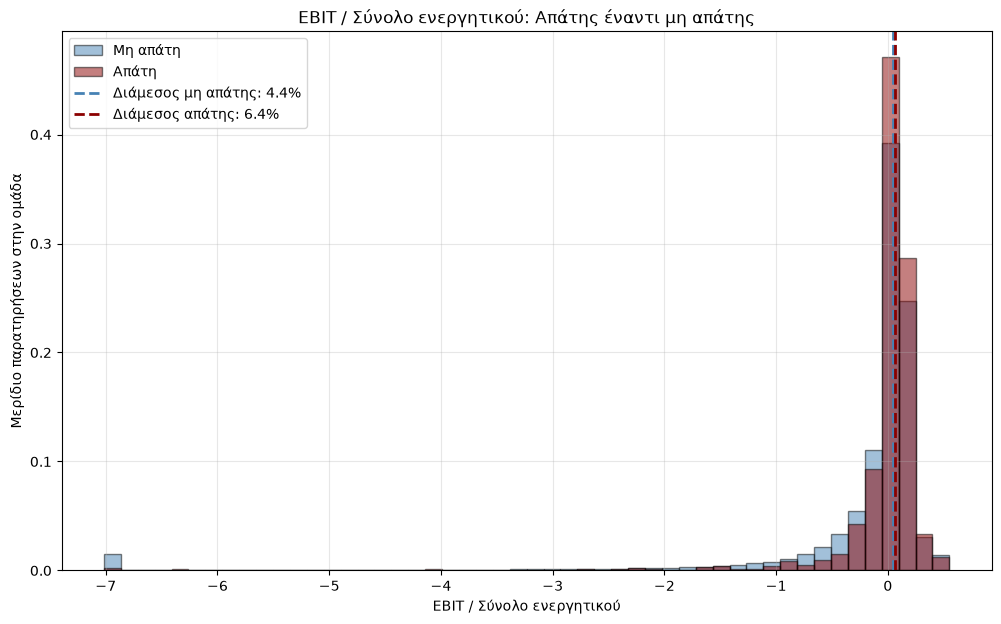

In [17]:
fraud = df.loc[df['misstate'] == 1, 'EBIT'].dropna()
non_fraud = df.loc[df['misstate'] == 0, 'EBIT'].dropna()

plt.figure(figsize=(12, 7))
plt.hist(non_fraud, bins=50,
         weights=np.ones(len(non_fraud)) / len(non_fraud),
         alpha=0.5, color='steelblue', edgecolor='black', label='Μη απάτη')
plt.hist(fraud, bins=50,
         weights=np.ones(len(fraud)) / len(fraud),
         alpha=0.5, color='darkred', edgecolor='black', label='Απάτη')

plt.axvline(non_fraud.median(), color='steelblue', linestyle='--', linewidth=2,
            label=f'Διάμεσος μη απάτης: {non_fraud.median():.1%}')
plt.axvline(fraud.median(), color='darkred', linestyle='--', linewidth=2,
            label=f'Διάμεσος απάτης: {fraud.median():.1%}')

plt.title('EBIT / Σύνολο ενεργητικού: Απάτης έναντι μη απάτης')
plt.xlabel('EBIT / Σύνολο ενεργητικού')
plt.ylabel('Μερίδιο παρατηρήσεων στην ομάδα')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Στο παραπάνω διάγραμμα η διάμεσος των δόλιων και μη επιχειρήσεων έχουν μια πολύ μικρή διαφορά της τάξης του 2%, όμως αυτή των δόλιων επιχειρήσεων είναι μεγαλύτερη (6,4 έναντι 4,4). Αυτο σημαίνει πως για το 50% των μη δόλιων παρατηρήσεων ο λόγος EBIT/Σύνολο ενεργητιού είναι κάτω από τα επίπεδα του 4,4%, δηλαδή για κάθε 100$ συνόλου του ενεργητικού υπάρχει κέρφοφορία έως και  4,4$ ενώ αντίστοιχα για το 50% των δόλιων για κάθε 100$ συνόλου του ενεργητικού υπάρχει κέρφοφορία έως και 6,4$

C:\Users\Φαίδρα\AppData\Local\Temp\ipykernel_6996\594244258.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='misstate', y='fyear', palette='Set2')


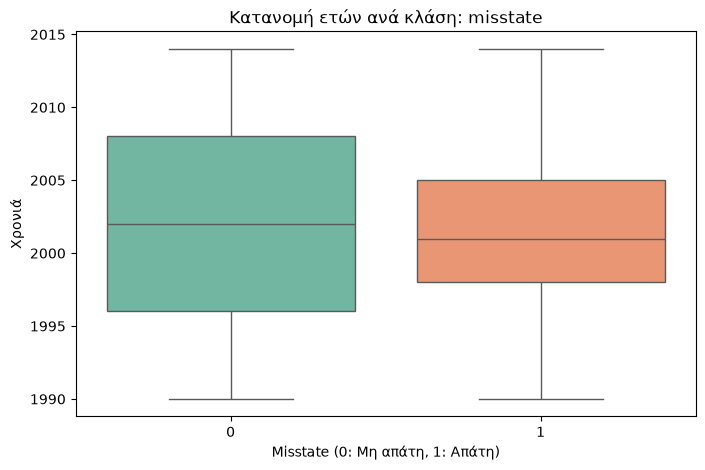

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='misstate', y='fyear', palette='Set2')
plt.title('Κατανομή ετών ανά κλάση: misstate')
plt.xlabel('Misstate (0: Μη απάτη, 1: Απάτη)')
plt.ylabel('Χρονιά')
plt.show()

#### Παρατηρούμε ότι για τις εταιρείες που έχουν διπράξει απάτη γύρω από τη χρονιά του 2000 υπάρχει μικρή διακύμανση και διασπορά των παρατηρήσεων 

## **ΚΑΘΑΡΙΣΜΟΣ ΔΕΔΟΜΕΝΩΝ**

In [19]:
#Αφαιρούμε τις παρατηρήσεις μετά το 2008 για να αποφύγουμε την επίδραση της χρηματοπιστωτικής κρίσης
df = df[df['fyear'] <= 2008].copy()
print (df.shape)
print (df['fyear'].min(), "-", df['fyear'].max())

(112981, 46)
1990 - 2008


In [20]:
#Το ποσοστό της κάθε κλάσης στην στήλη misstate (0 = No Fraud, 1 = Fraud) μετά την αφαίρεση των παρατηρήσεων μετά το 2008
print(df['misstate'].value_counts())
print(df['misstate'].value_counts(normalize=True) * 100) #εμφανιση σε ποσοστο

misstate
0    112129
1       852
Name: count, dtype: int64
misstate
0    99.245891
1     0.754109
Name: proportion, dtype: float64


In [21]:
# Ποσοστό ελλειπουσών τιμών ανά στήλη (%)
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False).head(10))

p_aaer     99.25
ch_cm      11.06
ch_cs      10.30
ch_roa      8.49
dpi         5.36
ch_fcf      3.37
ch_rsst     2.94
dch_wc      2.88
dch_rec     2.82
dch_inv     2.77
dtype: float64


In [22]:
# Στήλες που ελέγχουμε: όλες εκτός από p_aaer (υπάρχει μόνο στις απάτες)
check_cols = df.columns.drop('p_aaer')

# Πόσα κενά έχει κάθε γραμμή
missing_per_row = df[check_cols].isnull().sum(axis=1)

# Όριο: οι μισές στήλες
half = len(check_cols) / 2

# True όταν η γραμμή έχει κενά σε πάνω από τις μισές στήλες
many_missing = missing_per_row > half

print("Στήλες που ελέγχονται:", len(check_cols))
print("Όριο (μισές στήλες):", half)
print("Γραμμές με κενά σε πάνω από τις μισές στήλες:", many_missing.sum())
print("Μέγιστος αριθμός κενών σε μία γραμμή:", missing_per_row.max())

Στήλες που ελέγχονται: 45
Όριο (μισές στήλες): 22.5
Γραμμές με κενά σε πάνω από τις μισές στήλες: 0
Μέγιστος αριθμός κενών σε μία γραμμή: 13


In [23]:
# Δεν περιλαμβάνουμε την μεταβλητη p_aaer καθώς υπάρχει μόνο στις γραμμές που ειναι fraud 
# Στήλες "missing_values_cols" που εντοπίσαμε ότι έχουν τα περισσότερα missing values
missing_values_cols = ['ch_cm', 'ch_cs', 'ch_roa', 'dpi', 'ch_fcf', 
               'ch_rsst', 'dch_wc', 'dch_rec', 'dch_inv']

# Πόσες γραμμές έχουν τουλάχιστον ένα missing σε αυτές τις στήλες
missing_values = df[missing_values_cols].isnull().any(axis=1)
print(f"Γραμμές με missing σε missing_values_cols: {missing_values.sum()} "
      f"({missing_values.mean()*100:.2f}%)\n")

# Εμφνανιση ποσοστού misstate=1 για τς γραμμές που έχουν missing value
print("Ποσοστό misstate=1 ανάλογα με missing status")
print(df.groupby(missing_values)['misstate'].mean() * 100) # ο μέσος όρος ειναι ο αριθμός των fraud αφου το misstate ειναι 0 ή 1.

Γραμμές με missing σε missing_values_cols: 14092 (12.47%)

Ποσοστό misstate=1 ανάλογα με missing status
False    0.811010
True     0.354811
Name: misstate, dtype: float64


In [24]:
#Έλεγχος για διπλότυπα στις στήλες gvkey και fyear
dups = df.duplicated(subset=['gvkey', 'fyear'], keep=False)
print(f"Διπλότυπα: {dups.sum()}")

Διπλότυπα: 0


In [25]:
# Ποια είναι η πρώτη χρονιά κάθε εταιρείας στο dataset
first_year = df['fyear'] == df.groupby('gvkey')['fyear'].transform('min')

# Πίνακας: γραμμές με/χωρίς ελλείπουσες τιμές × πρώτη χρονιά ή όχι
print(pd.crosstab(missing_values, first_year,
                  rownames=['Ελλείπουσες τιμές'], colnames=['Πρώτη χρονιά'],
                  margins=True))

Πρώτη χρονιά       False   True     All
Ελλείπουσες τιμές                      
False              90915   7974   98889
True                6447   7645   14092
All                97362  15619  112981


##### Ο παραπάνω πίνακας μας δείχνει πως από το σύνολο των ελλειπούσων τιμών (14092) οι 7645 (54%) αντιστοιχούν στο πρώτο έτος μιας επιχείρησης στο δείγμα όπου οι μεταβλητές που συμβολίζουν μεταβολή δεν μπορούν να υπολογιστούν.

In [26]:
# Μεγέθη που οικονομικά δεν μπορεί να είναι αρνητικά και χρησιμοποιούνται στα scores
non_negative_cols = ['at', 'act', 'lct', 'lt', 'sale', 'cogs', 'rect', 'invt',
               'che', 'ppegt', 'dp', 'dltt', 'ap', 'csho', 'prcc_f']

for col in non_negative_cols:
    negative = df[col] < 0
    print(col,
          "| αρνητικές:", negative.sum(),
          "| απάτες σε αυτές:", df.loc[negative, 'misstate'].sum())

at | αρνητικές: 0 | απάτες σε αυτές: 0
act | αρνητικές: 8 | απάτες σε αυτές: 0
lct | αρνητικές: 0 | απάτες σε αυτές: 0
lt | αρνητικές: 0 | απάτες σε αυτές: 0
sale | αρνητικές: 26 | απάτες σε αυτές: 0
cogs | αρνητικές: 14 | απάτες σε αυτές: 0
rect | αρνητικές: 4 | απάτες σε αυτές: 0
invt | αρνητικές: 1 | απάτες σε αυτές: 0
che | αρνητικές: 27 | απάτες σε αυτές: 0
ppegt | αρνητικές: 0 | απάτες σε αυτές: 0
dp | αρνητικές: 1 | απάτες σε αυτές: 0
dltt | αρνητικές: 0 | απάτες σε αυτές: 0
ap | αρνητικές: 0 | απάτες σε αυτές: 0
csho | αρνητικές: 0 | απάτες σε αυτές: 0
prcc_f | αρνητικές: 0 | απάτες σε αυτές: 0


In [27]:
# Έλεγχος παρατηρήσεων με μηδενικό σύνολο ενεργητικού
zero_at = df['at'] == 0

print("Γραμμές με at = 0:", zero_at.sum())
print("Από αυτές δόλιες:", df.loc[zero_at, 'misstate'].sum())

# Πόσες κενές τιμές έχουν οι δείκτες που διαιρούν με το σύνολο ενεργητικού
print(df.loc[zero_at, ['EBIT', 'reoa', 'soft_assets']].isnull().sum())

Γραμμές με at = 0: 391
Από αυτές δόλιες: 0
EBIT           391
reoa           391
soft_assets    391
dtype: int64


##### Παρατηρούμε ότι το σύνολο ενεργητικού είναι μηδεν σε 391 παρατηρήσεις. Ωστόσο αποτελεί παρανομαστή στους δείκτες EBIΤ, reoa και soft_assets, συνεπώς σε 391 κελιά οι δείκτες αυτοί είναι κενοί καθώς δεν μπορεί να γίνει διαίρεση με το 0. Ωστόδο επειδή το πλήθος είναι μικρό οι παρατηρήσεις διατηρούνται.

In [28]:
# Αποθήκευση του καθαρισμένου df - το διαβάζει το 02_feature_engineering
df.to_pickle("df_clean.pkl")
print("Αποθηκεύτηκε:", df.shape)

Αποθηκεύτηκε: (112981, 46)
